Ce notebook presente le modele RF pour la variable cible 'TousAge_allergie_urgences'


In [1]:
import pandas as pd
import numpy as np

Merge_final = pd.read_csv("../data/final_metropole/Merge_final_2.csv")

Merge_final.info()

Merge_final.head()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 81 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  object 
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

C:\Users\gauxm\AppData\Local\Temp\ipykernel_24288\2492055701.py:4: DtypeWarning: Columns (1: code_dept) have mixed types. Specify dtype option on import or set low_memory=False.
  Merge_final = pd.read_csv("../data/final_metropole/Merge_final_2.csv")


,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,16.272727,20.909091,19.363636,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,22.257143,27.214286,13.928571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,14.635714,50.714286,8.214286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,21.864286,34.071429,11.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,21.028571,30.428571,15.714286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False


In [2]:
#NA
valeurs_manquantes = Merge_final.isnull().sum()
print(valeurs_manquantes[valeurs_manquantes > 0])

# Vérification du nombre de départements et de semaines
print(f"\nNombre de départements uniques : {Merge_final['code_dept'].unique()}")
print(f"Nombre de semaines uniques     : {Merge_final['date_semaine'].unique()}")


0an_bronchiolite_urgences             60
TousAge_allergie_hospitalisation      76
65plus_allergie_hospitalisation      106
0_14_allergie_hospitalisation        254
15_64_allergie_hospitalisation       118
0_14_asthme_hospitalisation          254
15_64_asthme_hospitalisation         118
TousAge_asthme_hospitalisation        76
65plus_asthme_hospitalisation        106
0an_bronchiolite_hospitalisation    1335
dtype: int64

Nombre de départements uniques : ['01' '02' '03' '04' '05' '06' '07' '08' '09' '10' '11' '12' '13' '14'
 '15' '16' '17' '18' '19' '21' '22' '23' '24' '25' '26' '27' '28' '29'
 '2A' '2B' '30' '31' '32' '33' '34' '35' '36' '37' '38' '39' 39 40 41 42
 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66
 67 68 69 70 71 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90
 91 92 93 94 95]
Nombre de semaines uniques     : <StringArray>
['2021-S01', '2021-S02', '2021-S03', '2021-S04', '2021-S05', '2021-S06',
 '2021-S07', '2021-S08', '2021-S09', '2021-S1

In [3]:
#Suppression colonnes
Merge_final_FS_MLA = Merge_final.drop(columns=[
    '0an_bronchiolite_urgences', 
    '65plus_allergie_urgences',
    '0_14_allergie_urgences',
    '15_64_allergie_urgences',
    '0_14_asthme_urgences',
    '15_64_asthme_urgences',
    'TousAge_asthme_urgences',
    '65plus_asthme_urgences',
    '0an_bronchiolite_hospitalisation',
    'TousAge_allergie_hospitalisation',
    '65plus_allergie_hospitalisation',
    '0_14_allergie_hospitalisation',
    '15_64_allergie_hospitalisation',
    '0_14_asthme_hospitalisation',
    '15_64_asthme_hospitalisation',
    'TousAge_asthme_hospitalisation',
    '65plus_asthme_hospitalisation',
    'Ntop_Maladie_Respi_Chronique_tsage_9',
    'Npop_Maladie_Respi_Chronique_tsage_9',
    'Ntop_Maladie_Respi_Chronique_0-14_9',
    'Ntop_Maladie_Respi_Chronique_15-64_9',
    'Ntop_Maladie_Respi_Chronique_65+_9',
    'Npop_Maladie_Respi_Chronique_0-14_9',
    'Npop_Maladie_Respi_Chronique_15-64_9',
    'Npop_Maladie_Respi_Chronique_65+_9',
    'nom_dep',])

Merge_final_FS_MLA.info()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 55 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  object 
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

In [4]:
#Met dans le bon type les variables

Merge_final_FS_MLA["code_dept"] = Merge_final_FS_MLA["code_dept"].astype("str")

Merge_final_FS_MLA['sos_present'] = Merge_final_FS_MLA['sos_present'].astype(int)

Merge_final_FS_MLA.info()

Merge_final_FS_MLA.head()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 55 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,16.272727,20.909091,19.363636,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,22.257143,27.214286,13.928571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,14.635714,50.714286,8.214286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,21.864286,34.071429,11.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,21.028571,30.428571,15.714286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0


In [5]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Calcul des matrices de corrélation sur les variables numériques
corr_pearson_FS = Merge_final_FS_MLA.select_dtypes(include=['float64', 'int64']).corr(method='pearson')
corr_spearman_FS = Merge_final_FS_MLA.select_dtypes(include=['float64', 'int64']).corr(method='spearman')

# Création des sous-graphiques côte à côte
fig = make_subplots(
    rows=1, cols=2, 
    subplot_titles=('Corrélation de Pearson (Linéaire)', 'Corrélation de Spearman (Monotone)'),
    horizontal_spacing=0.1
)

# Ajout de la heatmap Pearson
fig.add_trace(
    go.Heatmap(
        z=corr_pearson_FS.values,
        x=corr_pearson_FS.columns,
        y=corr_pearson_FS.index,
        colorscale='RdBu',
        zmin=-1, zmax=1,
        colorbar=dict(len=0.75, y=0.5)
    ),
    row=1, col=1
)

# Ajout de la heatmap Spearman
fig.add_trace(
    go.Heatmap(
        z=corr_spearman_FS.values,
        x=corr_spearman_FS.columns,
        y=corr_spearman_FS.index,
        colorscale='RdBu',
        zmin=-1, zmax=1,
        showscale=False # On masque la seconde barre d'échelle pour plus de clarté
    ),
    row=1, col=2
)

# Mise en page globale
fig.update_layout(
    title_text="Exploration Interactive des Corrélations - Master Dataset",
    height=800,
    width=1500,
    template="plotly_white"
)

# Masquer les étiquettes de l'axe des abscisses pour la figure de droite (col=2)
fig.update_yaxes(showticklabels=False, row=1, col=2)

# Affichage du graphique interactif
fig.show()

Étape 1 : Préparation du DataFrame & Découpage Temporel

In [6]:
# Copie de travail depuis Merge_final_FS_MLA
df = Merge_final_FS_MLA.copy()

# Extraction de l'année
df['annee'] = (
    df['date_semaine'].astype(str).str[:4].astype(int)
)

# Split temporel strict
df_train = df[df['annee'] <= 2022]
df_val = df[df['annee'] == 2023]
df_test = df[df['annee'] == 2024]

df.info()

df_test.info()

df_test.head()


<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 56 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present,annee
156,2024-S01,01,0.667750,0.650833,0.086167,2.0555,0.003767,14.357143,42.928571,8.000000,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
157,2024-S02,01,0.509437,0.638333,0.061333,1.7920,0.002724,16.242857,22.714286,30.785714,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
158,2024-S03,01,0.741125,1.568333,0.096500,1.8685,0.004689,16.784615,34.928571,16.727273,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
159,2024-S04,01,0.557813,1.220000,0.074167,1.9375,0.003691,21.714286,29.071429,15.250000,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
160,2024-S05,01,0.704500,1.590000,0.141833,2.6190,0.004768,18.478571,35.500000,19.142857,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024


Étape 2 : Feature Engineering (Inertie & Saisons)

In [7]:
# Extraction du numéro de semaine (ex: "2021-S01" -> 1.0)
semaines = df['date_semaine'].astype(str).str.split('S').str[1].astype(float)

# Encodage cyclique (sinus / cosinus)
df['semaine_sin'] = np.sin(2 * np.pi * semaines / 52)
df['semaine_cos'] = np.cos(2 * np.pi * semaines / 52)
  
# Variable de retard (lag 1) par département dans l'ordre chronologique
df = df.sort_values(['code_dept', 'date_semaine'])
df['target_lag_1'] = df.groupby('code_dept')['TousAge_allergie_urgences'].shift(1)

# Nettoyage de la première ligne historique par département (qui a un NaN sur le lag)
df = df.dropna(subset=['target_lag_1'])

# Mise à jour des splits Train / Val / Test avec les nouvelles features
df_train = df[df['annee'] <= 2022].copy()
df_val = df[df['annee'] == 2023].copy()
df_test = df[df['annee'] == 2024].copy()

# Vérification rapide
print(f'Train : {df_train.shape} | Val : {df_val.shape} | Test : {df_test.shape}')


Train : (9888, 59) | Val : (4992, 59) | Test : (4992, 59)


Étape 3 : Preprocessing pour RF

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

#Colonnes à exclure des features (X)
cols_to_drop = ['TousAge_allergie_urgences', 'date_semaine', 'annee']
cols_to_drop = [c for c in cols_to_drop if c in df.columns]

# Séparation X / y pour chaque split
X_train = df_train.drop(columns=cols_to_drop)
y_train = df_train['TousAge_allergie_urgences']

X_val = df_val.drop(columns=cols_to_drop)
y_val = df_val['TousAge_allergie_urgences']

X_test = df_test.drop(columns=cols_to_drop)
y_test = df_test['TousAge_allergie_urgences']

# Identification explicite des colonnes catégorielles
cat_cols = ['code_dept']

# Construction du préprocesseur pour le RF
preprocessor_RF= ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)],
        remainder='passthrough'
)

# Application (Fit sur le Train uniquement, Transform sur Val et Test)
X_train_RF = preprocessor_RF.fit_transform(X_train)
X_val_RF = preprocessor_RF.transform(X_val)
X_test_RF = preprocessor_RF.transform(X_test)

print('\nDimensions après preprocessing RF :')
print(f'X_train_knn : {X_train_RF.shape}')
print(f'X_val_knn   : {X_val_RF.shape}')
print(f'X_test_knn  : {X_test_RF.shape}')


Dimensions après preprocessing RF :
X_train_knn : (9888, 151)
X_val_knn   : (4992, 151)
X_test_knn  : (4992, 151)


Étape 4 : Calcul des Baselines sur Train, Val et Test 

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Fonction d'affichage rapide pour standardiser les résultats
def eval_metrics(y_true, y_pred, name_split, name_baseline):
  r2 = r2_score(y_true, y_pred)
  rmse = np.sqrt(mean_squared_error(y_true, y_pred))
  mae = mean_absolute_error(y_true, y_pred)
  print(
      f'[{name_baseline}] {name_split} -> R2: {r2:.4f} | RMSE: {rmse:.4f} |'
      f' MAE: {mae:.4f}'
  )

##Baseline persistance
# La prédiction est simplement la variable target_lag_1
eval_metrics(y_train, X_train['target_lag_1'], 'Train', 'Persistance')
eval_metrics(y_val, X_val['target_lag_1'], 'Val (2023)', 'Persistance')
eval_metrics(y_test, X_test['target_lag_1'], 'Test (2024)', 'Persistance')

##baseline Moyenne historique
# Extraction du numéro de semaine (ex: "2021-S01" -> 1.0) pour le calcul historique
df_train_copy = df_train.copy()
df_train_copy['semaine_num'] = (
    df_train_copy['date_semaine'].astype(str).str.split('S').str[1].astype(float)
)

# Calcul de la moyenne par (code_dept, semaine_num) uniquement sur le Train (2021-2022)
moy_hist = (
    df_train_copy.groupby(['code_dept', 'semaine_num'])[
        'TousAge_allergie_urgences'
    ]
    .mean()
    .reset_index()
)

# Fonction interne pour assigner la moyenne historique à n'importe quel split
def get_moy_hist_preds(data_split):
  temp = data_split.copy()
  temp['semaine_num'] = (
      temp['date_semaine'].astype(str).str.split('S').str[1].astype(float)
  )
  merged = temp.merge(
      moy_hist, on=['code_dept', 'semaine_num'], how='left', suffixes=('', '_moy')
  )
  # Si une combinaison département/semaine n'existe pas dans le train, on remplace par la moyenne globale du train
  return merged['TousAge_allergie_urgences_moy'].fillna(y_train.mean())


# Évaluation de la moyenne historique sur les 3 splits
eval_metrics(y_train, get_moy_hist_preds(df_train), 'Train', 'Moyenne Hist.')
eval_metrics(y_val, get_moy_hist_preds(df_val), 'Val (2023)', 'Moyenne Hist.')
eval_metrics(y_test, get_moy_hist_preds(df_test), 'Test (2024)', 'Moyenne Hist.')

[Persistance] Train -> R2: 0.0719 | RMSE: 310.8454 | MAE: 222.9904
[Persistance] Val (2023) -> R2: 0.1041 | RMSE: 306.1080 | MAE: 219.0278
[Persistance] Test (2024) -> R2: 0.0348 | RMSE: 287.9188 | MAE: 206.7123
[Moyenne Hist.] Train -> R2: 0.6957 | RMSE: 177.9876 | MAE: 128.2105
[Moyenne Hist.] Val (2023) -> R2: 0.2480 | RMSE: 280.4511 | MAE: 203.9206
[Moyenne Hist.] Test (2024) -> R2: 0.0541 | RMSE: 285.0372 | MAE: 210.2151


Étape 5 : Entraînement & Optimisation des Modèles

In [10]:
from sklearn.ensemble import RandomForestRegressor

# Grille d'hyperparamètres à tester
param_grid = [
    {'n_estimators': 100, 'max_depth': 15, 'min_samples_leaf': 2, 'max_features': 'sqrt',},
    {'n_estimators': 200, 'max_depth': 25, 'min_samples_leaf': 1, 'max_features': 'sqrt'},
    {'n_estimators': 200, 'max_depth': 35, 'min_samples_leaf': 2, 'max_features': 1.0},
    {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 4, 'max_features': 'sqrt'},
    {'n_estimators': 100, 'max_depth': 20, 'min_samples_leaf': 1, 'max_features': 1.0},
    {'n_estimators': 200, 'max_depth': 20, 'min_samples_leaf': 5, 'max_features': 'sqrt'}
]

best_score = -np.inf
best_params = None
best_rf = None

# Recherche manuelle guidée par la performance sur le Val (2023)
for params in param_grid:
    rf = RandomForestRegressor(**params, random_state=42, n_jobs=-1, min_samples_split=15)
    rf.fit(X_train_RF, y_train)
    
    # Évaluation sur le jeu de validation
    y_val_pred = rf.predict(X_val_RF)
    score_val = r2_score(y_val, y_val_pred)
    
    print(f"Paramètres: {params} | R2 Val: {score_val:.4f}")
    
    if score_val > best_score:
        best_score = score_val
        best_params = params
        best_rf = rf

print('Meilleurs paramètres sélectionnés (sur Val)')
print(best_params, f"-> R2 Val: {best_score:.4f}")

# Évaluation finale sur les 3 splits avec le meilleur modèle
print('Performances Finales du Random Forest Optimisé')
eval_metrics(y_train, best_rf.predict(X_train_RF), 'Train', 'RF Optimisé')
eval_metrics(y_val, best_rf.predict(X_val_RF), 'Val (2023)', 'RF Optimisé')


Paramètres: {'n_estimators': 100, 'max_depth': 15, 'min_samples_leaf': 2, 'max_features': 'sqrt'} | R2 Val: 0.4361
Paramètres: {'n_estimators': 200, 'max_depth': 25, 'min_samples_leaf': 1, 'max_features': 'sqrt'} | R2 Val: 0.4394
Paramètres: {'n_estimators': 200, 'max_depth': 35, 'min_samples_leaf': 2, 'max_features': 1.0} | R2 Val: 0.4325
Paramètres: {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 4, 'max_features': 'sqrt'} | R2 Val: 0.4394
Paramètres: {'n_estimators': 100, 'max_depth': 20, 'min_samples_leaf': 1, 'max_features': 1.0} | R2 Val: 0.4285
Paramètres: {'n_estimators': 200, 'max_depth': 20, 'min_samples_leaf': 5, 'max_features': 'sqrt'} | R2 Val: 0.4380
Meilleurs paramètres sélectionnés (sur Val)
{'n_estimators': 200, 'max_depth': 25, 'min_samples_leaf': 1, 'max_features': 'sqrt'} -> R2 Val: 0.4394
Performances Finales du Random Forest Optimisé
[RF Optimisé] Train -> R2: 0.7480 | RMSE: 161.9743 | MAE: 117.0796
[RF Optimisé] Val (2023) -> R2: 0.4394 | RMSE: 242.1

Étape 6 : Validation Finale sur Test (2024)

In [11]:
# Prédiction et évaluation du meilleur KNN sur le Test
y_test_pred_RF = best_rf.predict(X_test_RF)
eval_metrics(y_test, best_rf.predict(X_test_RF), 'Test (2024)', 'RF Optimisé')

# Comparaison directe avec les Baselines sur le Test
print('Comparaison avec les Baselines (Test 2024)')
eval_metrics(y_test, X_test['target_lag_1'], 'Test (2024)', 'Persistance')
eval_metrics(y_test, get_moy_hist_preds(df_test), 'Test (2024)', 'Moyenne Hist.')


[RF Optimisé] Test (2024) -> R2: 0.3567 | RMSE: 235.0497 | MAE: 174.7552
Comparaison avec les Baselines (Test 2024)
[Persistance] Test (2024) -> R2: 0.0348 | RMSE: 287.9188 | MAE: 206.7123
[Moyenne Hist.] Test (2024) -> R2: 0.0541 | RMSE: 285.0372 | MAE: 210.2151


Étape 7 : représentation résultats et comparaison entre prédict et réel

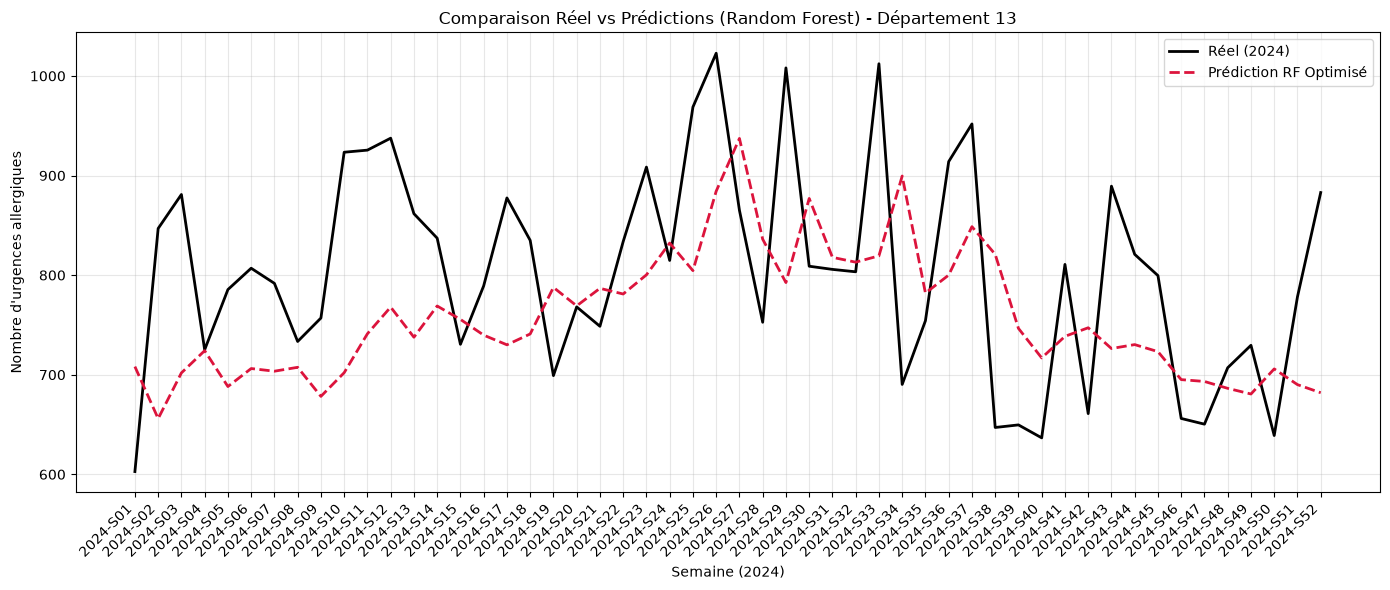

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Création du DataFrame de résultats sur le Test (2024)
df_results_test = df_test.copy()
df_results_test['pred'] = best_rf.predict(X_test_RF)

# 2. Visualisation pour un département cible (ex: '13')
dept_cible = '13'
df_dept = df_results_test[df_results_test['code_dept'] == dept_cible].sort_values(
    'date_semaine'
)

plt.figure(figsize=(14, 6))
plt.plot(
    df_dept['date_semaine'],
    df_dept['TousAge_allergie_urgences'],
    label='Réel (2024)',
    color='black',
    linewidth=2,
)
plt.plot(
    df_dept['date_semaine'],
    df_dept['pred'],
    label='Prédiction RF Optimisé',
    color='crimson',
    linestyle='--',
    linewidth=2,
)

plt.title(
    f"Comparaison Réel vs Prédictions (Random Forest) - Département {dept_cible}"
)
plt.xlabel('Semaine (2024)')
plt.ylabel("Nombre d'urgences allergiques")
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

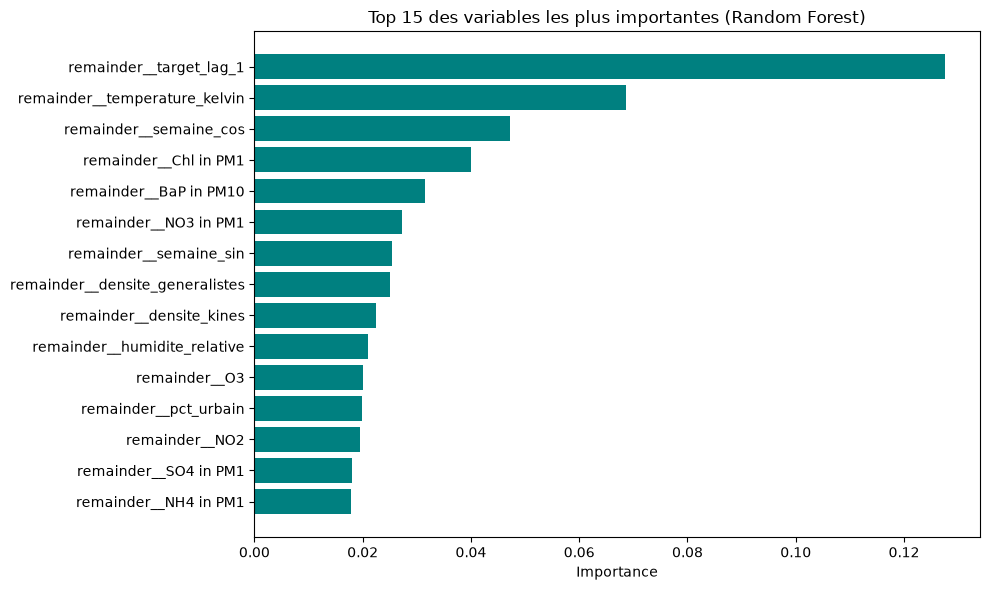

In [13]:
feature_names = preprocessor_RF.get_feature_names_out()

# Création du DataFrame propre avec les vrais noms
df_importances = pd.DataFrame({
    'Feature': feature_names,
    'Importance': best_rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

# Affichage du graphique avec les vrais noms
plt.figure(figsize=(10, 6))
plt.barh(df_importances['Feature'][:15][::-1], df_importances['Importance'][:15][::-1], color='teal')
plt.xlabel("Importance")
plt.title("Top 15 des variables les plus importantes (Random Forest)")
plt.tight_layout()
plt.show()